# 02 · From patterns to a strategy: last-10-second momentum

**My approach.** I first look for a robust pattern in the 1-second data, then build the simplest strategy that exploits it, test it honestly, and finally add a risk-management layer.

1. Patterns in the data: regimes, a structural break in March 2023, and short-horizon momentum
2. Where the predictive information sits inside each minute, plus formal time-series tests
3. Strategy rule and baseline backtest (in-sample 2023–2024, out-of-sample 2025–Oct 2026)
4. Robustness checks, sensitivity to the signal window and a note on data snooping
5. Risk management: volatility-targeted sizing and a daily loss limit
6. Comparison with classic BTC strategies
7. Market context: how the strategy behaves on major news days
8. Cost sensitivity, conclusions, limitations and next steps

Appendix: time of day. A robustness check on the signal window is in notebook 03.

Input: the 1-minute bars and monthly statistics produced by `01_retrieve_and_process_data.ipynb` (folder `data_1min`).

**Backtest conventions.** A position decided at the close of minute $t$ earns the log return from close $t$ to close $t+1$, so no future information is used. Returns are reported on 1× notional and **not compounded** (sum of log returns). Per the brief, transaction costs are excluded from the headline results and analysed separately in section 8. Because the edge per trade is small, I report **bp per minute and breakeven cost first**; annualised Sharpe ratios on minute data without costs look very large and should be read with that in mind.

In [1]:
import glob, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#2a6fdb", "#e8833a", "#8a8a8a"
SPLIT = "2025-01-01"                  # in-sample before, out-of-sample from this date
MIN_PER_YEAR = 365 * 24 * 60          # crypto trades 24/7

files = sorted(glob.glob("data_1min/BTCUSDT-1min-*.parquet"))
m = pd.concat([pd.read_parquet(f) for f in files]).sort_index()
m = m[~m.index.duplicated()]
stats = pd.read_csv("data_1min/monthly_stats.csv")

m["ret"] = np.log(m["close"]).diff()                 # 1-minute log return
print(f"{len(m):,} one-minute bars | {m.index[0]} to {m.index[-1]}")
print(f"built from {stats['raw_rows'].sum():,} one-second klines, all checksums OK: {bool(stats['checksum_ok'].all())}")

2,016,000 one-minute bars | 2023-01-01 00:00:00 to 2026-10-31 23:59:00
built from 120,951,229 one-second klines, all checksums OK: True


## 1 · Patterns in the data

### 1a · Market regimes
Daily realized volatility is computed from 1-second returns ($\sqrt{\sum r_i^2}$ over the day, annualised).

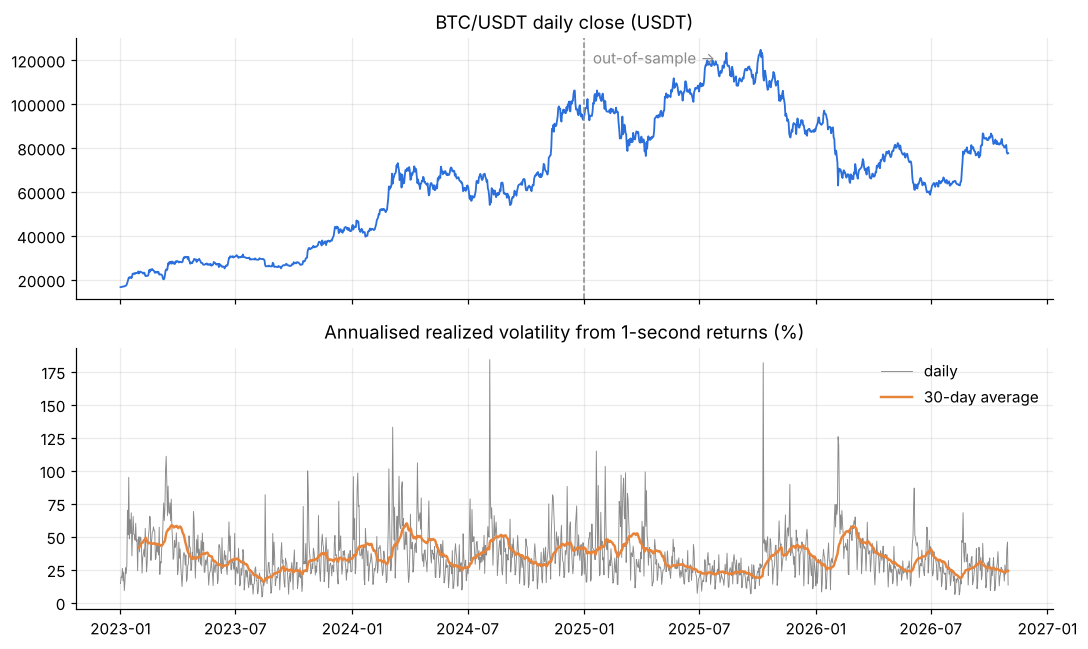

,first,last,avg_vol,usd_volume_bn,price_change
2023,16616.75,42283.58,0.336,2.520,1.545
2024,44179.55,93576.00,0.397,2.322,1.118
2025,94591.79,87648.22,0.330,2.102,-0.073
2026,88839.04,77582.02,0.324,1.313,-0.127


In [2]:
d = pd.DataFrame({"close": m["close"].resample("1D").last(),
                  "rv": m["rv"].resample("1D").sum(),
                  "usd_volume": m["quote_volume"].resample("1D").sum(),
                  "trades": m["trades"].resample("1D").sum(),
                  "active_secs": m["active_secs"].resample("1D").sum()})
d["vol_ann"] = np.sqrt(d["rv"] * 365)
d["zero_trade_share"] = 1 - d["active_secs"] / 86400

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(d.index, d["close"], color=BLUE, lw=1.2); ax[0].set_title("BTC/USDT daily close (USDT)")
ax[0].axvline(pd.Timestamp(SPLIT), color=GREY, ls="--", lw=1); ax[0].text(pd.Timestamp(SPLIT), d["close"].max()*0.95, "  out-of-sample →", color=GREY)
ax[1].plot(d.index, d["vol_ann"]*100, color=GREY, lw=0.6, label="daily")
ax[1].plot(d.index, d["vol_ann"].rolling(30).mean()*100, color=ORANGE, lw=1.6, label="30-day average")
ax[1].set_title("Annualised realized volatility from 1-second returns (%)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("fig_1a_regimes.png", bbox_inches="tight"); plt.show()

yearly = d.groupby(d.index.year).agg(first=("close", "first"), last=("close", "last"),
                                    avg_vol=("vol_ann", "mean"), usd_volume_bn=("usd_volume", "mean"))
yearly["price_change"] = yearly["last"] / yearly["first"] - 1
yearly["usd_volume_bn"] /= 1e9
yearly.round(3)

### 1b · A structural break on 22 March 2023

Binance ended zero-fee trading on BTC/USDT on 22 March 2023. The 1-second data shows the market microstructure changing on that date: seconds with no trades go from almost none to a material share, and the lag-1 autocorrelation of 1-second returns flips from **negative** (bid-ask bounce, prices flicking back and forth) to **positive** (price moves continue for a few seconds).

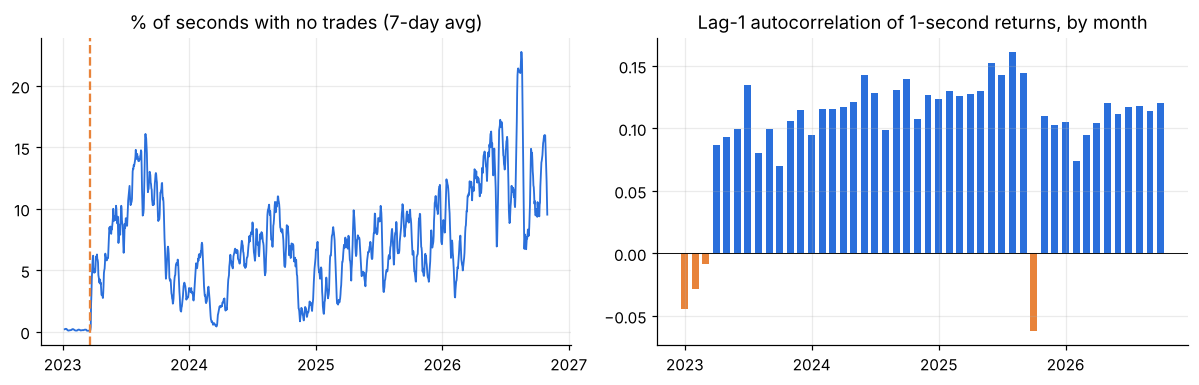

,3 weeks before,3 weeks after
trades per day,9884477.238,1268770.810
USD volume per day ($bn),9.703,1.772
share of seconds with no trades,0.001,0.056


In [3]:
stats["month_dt"] = pd.to_datetime(stats["month"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(d.index, d["zero_trade_share"].rolling(7).mean()*100, color=BLUE, lw=1.2)
ax[0].axvline(pd.Timestamp("2023-03-22"), color=ORANGE, ls="--"); ax[0].set_title("% of seconds with no trades (7-day avg)")
ax[1].bar(stats["month_dt"], stats["autocorr_1s"], width=20,
          color=[ORANGE if v < 0 else BLUE for v in stats["autocorr_1s"]])
ax[1].axhline(0, color="k", lw=0.6); ax[1].set_title("Lag-1 autocorrelation of 1-second returns, by month")
for a in ax:
    a.xaxis.set_major_locator(mdates.YearLocator()); a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.savefig("fig_1b_structural_break.png", bbox_inches="tight"); plt.show()

before = d.loc["2023-03-01":"2023-03-21"]; after = d.loc["2023-03-23":"2023-04-12"]
pd.DataFrame({"3 weeks before": [before["trades"].mean(), before["usd_volume"].mean()/1e9, before["zero_trade_share"].mean()],
              "3 weeks after":  [after["trades"].mean(),  after["usd_volume"].mean()/1e9,  after["zero_trade_share"].mean()]},
             index=["trades per day", "USD volume per day ($bn)", "share of seconds with no trades"]).round(3)

### 1c · Short-horizon momentum

The variance ratio compares the variance of $k$-second returns with $k$ times the variance of 1-second returns:
$$VR(k) = \frac{\operatorname{Var}(r_t^{(k)})}{k\,\operatorname{Var}(r_t^{(1)})}$$
$VR = 1$ for a random walk. Since April 2023, $VR$ is consistently **above 1** at horizons from 10 seconds to an hour: short-term moves tend to continue. This is the pattern the strategy exploits.

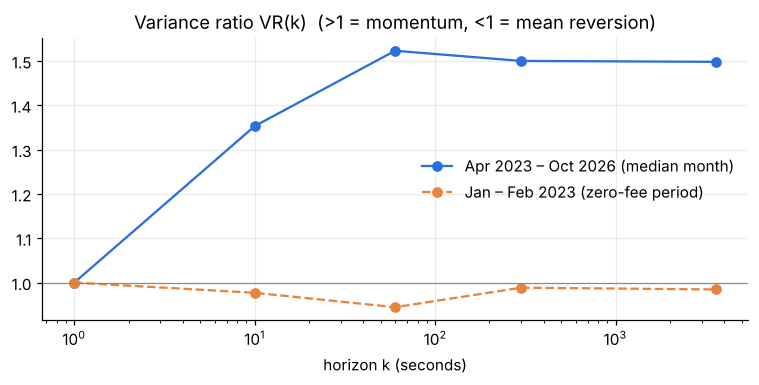

,VR_10s,VR_60s,VR_300s,VR_3600s
median,1.35,1.52,1.50,1.50
min,1.05,1.06,1.27,0.83
max,1.54,1.90,2.72,2.00


In [4]:
vr_cols = ["VR_10s", "VR_60s", "VR_300s", "VR_3600s"]
post = stats[stats["month_dt"] >= "2023-04-01"]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot([1, 10, 60, 300, 3600], [1] + list(post[vr_cols].median()), "o-", color=BLUE, label="Apr 2023 – Oct 2026 (median month)")
ax.plot([1, 10, 60, 300, 3600], [1] + list(stats[stats["month_dt"] < "2023-03-01"][vr_cols].median()), "o--", color=ORANGE, label="Jan – Feb 2023 (zero-fee period)")
ax.axhline(1, color=GREY, lw=0.8); ax.set_xscale("log"); ax.set_xlabel("horizon k (seconds)")
ax.set_title("Variance ratio VR(k)  (>1 = momentum, <1 = mean reversion)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("fig_1c_variance_ratio.png", bbox_inches="tight"); plt.show()
post[vr_cols].agg(["median", "min", "max"]).round(2)

## 2 · Where does the predictive information sit inside a minute?

Each minute is split into its first 50 seconds and its last 10 seconds (`ret_last10s`, computed from 1-second data in notebook 01). Taking a position in the direction of each part and holding it for the next minute shows that **the last 10 seconds carry most of the information**, and that it is used up quickly: entering one minute later earns almost nothing.

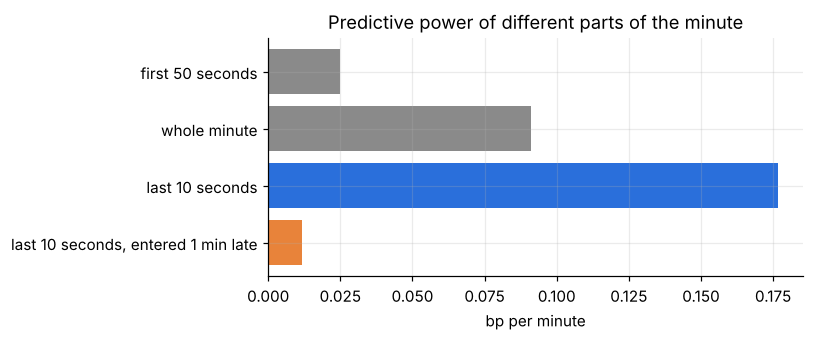

,signal,avg next-minute return in signal direction (bp)
0,first 50 seconds,0.025
1,whole minute,0.091
2,last 10 seconds,0.177
3,"last 10 seconds, entered 1 min late",0.012


In [5]:
fwd1 = m["ret"].shift(-1)                      # next-minute return
fwd2 = m["ret"].shift(-2)                      # the minute after (1-minute delay)
first50 = m["ret"] - m["ret_last10s"]

def bp_per_min(signal, fwd):
    return float((np.sign(signal) * fwd).mean() * 1e4)

info = pd.DataFrame({
    "signal": ["first 50 seconds", "whole minute", "last 10 seconds", "last 10 seconds, entered 1 min late"],
    "avg next-minute return in signal direction (bp)": [
        bp_per_min(first50, fwd1), bp_per_min(m["ret"], fwd1),
        bp_per_min(m["ret_last10s"], fwd1), bp_per_min(m["ret_last10s"], fwd2)]})
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(info["signal"], info.iloc[:, 1], color=[GREY, GREY, BLUE, ORANGE]); ax.invert_yaxis()
ax.set_xlabel("bp per minute"); ax.set_title("Predictive power of different parts of the minute")
plt.tight_layout(); plt.savefig("fig_2_information.png", bbox_inches="tight"); plt.show()
info.round(3)

## 2b · Formal time-series tests

Three questions, tested with the random-walk and volatility tests of a standard financial econometrics course (Campbell, Lo and MacKinlay, ch. 2; Engle 1982; Bollerslev 1986; Glosten, Jagannathan and Runkle 1993), mostly on the period after the structural break:

1. **Volatility clustering**. do large moves follow large moves? Tested with the autocorrelation function (ACF) of absolute returns, the Ljung-Box test on squared returns, Engle's ARCH LM test and a GARCH(1,1) model. Clustering says nothing about direction, but it matters for risk and position sizing.
2. **Does the sign of the last 10 seconds continue?** The Cowles–Jones ratio counts sequences (same sign) against reversals; it equals 1 under a random walk.
3. **Is the trading signal statistically significant?** The strategy's mean return is tested with Newey-West (HAC) standard errors, which allow for autocorrelation and changing volatility in the returns.

Ljung-Box statistic for $m$ lags, with $\hat\rho_k$ the sample autocorrelation at lag $k$:
$$Q = n(n+2)\sum_{k=1}^{m}\frac{\hat\rho_k^2}{n-k} \sim \chi^2_m$$
GARCH(1,1) conditional variance:
$$\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$
$\alpha + \beta$ close to 1 means volatility shocks die out slowly; the half-life is $\ln 0.5 / \ln(\alpha+\beta)$.

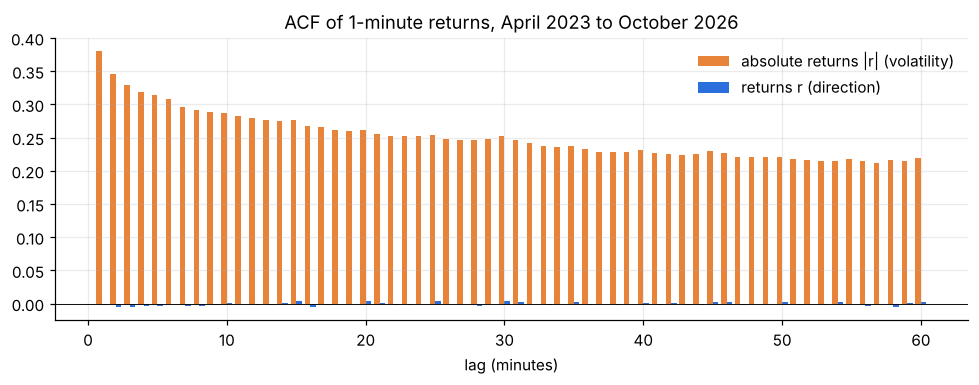

ACF of |r|: lag 1 = 0.38, lag 60 = 0.22 | ACF of r: lag 1 = -0.002


,series,lags (min),Ljung-Box Q,p-value
0,returns,10,227,3.672421e-43
1,returns,60,743,1.960962e-118
2,squared returns,10,377946,0.000000e+00
3,squared returns,60,553834,0.000000e+00


In [6]:
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import het_arch
import statsmodels.api as sm

post_break = m.loc["2023-04-01":]
r = post_break["ret"].dropna()

def ljung_box(x, lags):            # same statistic as statsmodels' acorr_ljungbox, computed via FFT for 1.9m rows
    rho = acf(x, nlags=lags, fft=True)
    n, k = len(x), np.arange(1, lags + 1)
    q = n * (n + 2) * np.sum(rho[1:] ** 2 / (n - k))
    return q, stats.chi2.sf(q, lags)

acf_ret, acf_abs = acf(r, nlags=60, fft=True), acf(r.abs(), nlags=60, fft=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(np.arange(1, 61) - 0.2, acf_abs[1:], width=0.4, color=ORANGE, label="absolute returns |r| (volatility)")
ax.bar(np.arange(1, 61) + 0.2, acf_ret[1:], width=0.4, color=BLUE, label="returns r (direction)")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("lag (minutes)"); ax.legend(frameon=False)
ax.set_title("ACF of 1-minute returns, April 2023 to October 2026")
plt.tight_layout(); plt.savefig("fig_2b_acf.png", bbox_inches="tight"); plt.show()

rows = []
for name, x in [("returns", r), ("squared returns", r ** 2)]:
    for lags in [10, 60]:
        q, p = ljung_box(x, lags)
        rows.append({"series": name, "lags (min)": lags, "Ljung-Box Q": round(q), "p-value": p})
print(f"ACF of |r|: lag 1 = {acf_abs[1]:.2f}, lag 60 = {acf_abs[60]:.2f} | ACF of r: lag 1 = {acf_ret[1]:.3f}")
pd.DataFrame(rows)

In [7]:
daily = np.log(post_break["close"].resample("1D").last()).diff().dropna() * 100   # daily returns in %
lm_stat, lm_p, _, _ = het_arch(daily, nlags=10)
print(f"Engle ARCH LM test (daily, 10 lags): LM = {lm_stat:.1f}, p = {lm_p:.2g}")

try:
    from arch import arch_model           # if missing: run  pip install arch  in a cell and restart the kernel
    garch = arch_model(daily, vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    a, b = garch.params["alpha[1]"], garch.params["beta[1]"]
    print(f"GARCH(1,1), daily, Student-t errors: alpha = {a:.3f}, beta = {b:.3f}, alpha + beta = {a + b:.3f}, "
          f"half-life = {np.log(0.5) / np.log(a + b):.0f} days")
    print(garch.summary().tables[2])
except ImportError:
    print("Package 'arch' not installed: run  pip install arch  to fit the GARCH model.")

Engle ARCH LM test (daily, 10 lags): LM = 79.7, p = 5.9e-13
GARCH(1,1), daily, Student-t errors: alpha = 0.058, beta = 0.932, alpha + beta = 0.990, half-life = 70 days
                              Volatility Model                             
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.1409      0.117      1.204      0.229 [-8.848e-02,  0.370]
alpha[1]       0.0583  2.394e-02      2.435  1.488e-02  [1.138e-02,  0.105]
beta[1]        0.9318  3.078e-02     30.277 2.281e-201    [  0.872,  0.992]


In [8]:
# significance of the trading signal: mean strategy return with Newey-West (HAC) standard errors
signal = np.sign(m["ret_last10s"])
strat = (signal * m["ret"].shift(-1)).dropna() * 1e4          # bp per minute
rows = []
for name, mask in [("in-sample 2023-24", strat.index < SPLIT), ("out-of-sample 2025-26", strat.index >= SPLIT)]:
    fit = sm.OLS(strat[mask], np.ones(mask.sum())).fit(cov_type="HAC", cov_kwds={"maxlags": 60})
    rows.append({"period": name, "mean (bp/min)": fit.params.iloc[0], "HAC t-stat": fit.tvalues.iloc[0]})
print(pd.DataFrame(rows).round(3), "\n")

# the edge by size of the last-10-second move: medium moves continue most, the very largest a little less
df = pd.DataFrame({"pnl": (signal * m["ret"].shift(-1)) * 1e4, "size": m["ret_last10s"].abs()}).dropna()
df = df[df["size"] > 0]
df["quintile of |last-10s move|"] = pd.qcut(df["size"].rank(method="first"), 5, labels=["1 smallest", "2", "3", "4", "5 largest"])
df.groupby("quintile of |last-10s move|", observed=True)["pnl"].mean().round(3).to_frame("avg bp per minute")

                  period  mean (bp/min)  HAC t-stat
0      in-sample 2023-24          0.167      25.384
1  out-of-sample 2025-26          0.187      29.928 



,avg bp per minute
quintile of |last-10s move|,
1 smallest,0.039
2,0.287
3,0.303
4,0.267
5 largest,0.192


In [9]:
# Cowles-Jones (1937) ratio: sequences (same sign) / reversals, here between the last-10-second move and the next minute.
# Under a random walk with a symmetric distribution CJ = 1; the share of sequences pi_s is binomial, so z = (pi_s - 0.5) / sqrt(0.25 / N).
s_now, s_next = np.sign(m["ret_last10s"]), np.sign(m["ret"].shift(-1))
rows = []
for name, mask in [("zero-fee period (to 21 Mar 2023)", m.index < "2023-03-22"),
                   ("in-sample, Apr 2023 - Dec 2024", (m.index >= "2023-04-01") & (m.index < SPLIT)),
                   ("out-of-sample, 2025 - Oct 2026", m.index >= SPLIT)]:
    a, b = s_now[mask], s_next[mask]
    keep = (a != 0) & (b != 0)
    n_s, n_r = int((a[keep] == b[keep]).sum()), int((a[keep] != b[keep]).sum())
    pi_s = n_s / (n_s + n_r)
    rows.append({"period": name, "sequences N_s": n_s, "reversals N_r": n_r, "CJ = N_s / N_r": n_s / n_r,
                 "z-stat (pi_s = 0.5)": (pi_s - 0.5) / np.sqrt(0.25 / (n_s + n_r))})
pd.DataFrame(rows).set_index("period").round(4)

,sequences N_s,reversals N_r,CJ = N_s / N_r,z-stat (pi_s = 0.5)
period,,,,
zero-fee period (to 21 Mar 2023),55728,59170,0.9418,-10.1544
"in-sample, Apr 2023 - Dec 2024",367700,347859,1.0570,23.4553
"out-of-sample, 2025 - Oct 2026",386363,363952,1.0616,25.8726


In [10]:
# leverage effect? GJR-GARCH adds gamma * eps^2 * 1{eps < 0}: volatility rising more after falls than after rises
try:
    from arch import arch_model
    fits = {name: arch_model(daily, vol="GARCH", p=1, o=o, q=1, dist="t").fit(disp="off") for name, o in [("GARCH(1,1)", 0), ("GJR-GARCH(1,1)", 1)]}
    gjr = fits["GJR-GARCH(1,1)"]
    print(f"GJR gamma = {gjr.params['gamma[1]']:.3f} (t = {gjr.tvalues['gamma[1]']:.2f}, p = {gjr.pvalues['gamma[1]']:.2f})")
    display(pd.DataFrame({name: {"AIC": f.aic, "BIC": f.bic} for name, f in fits.items()}).T.round(1))
except ImportError:
    print("Package 'arch' not installed: run  pip install arch")

GJR gamma = 0.060 (t = 1.59, p = 0.11)


,AIC,BIC
"GARCH(1,1)",5730.8,5756.7
"GJR-GARCH(1,1)",5727.5,5758.6


In [11]:
# GARCH(1,1) residual diagnostics: if the model is adequate, standardized residuals z = eps / sigma
# should show no remaining autocorrelation in z or z^2 (Ljung-Box) and no remaining ARCH effect
try:
    from arch import arch_model
    g = arch_model(daily, vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    z_std = g.std_resid.dropna()
    diag = []
    for name, x in [("z", z_std), ("z squared", z_std ** 2)]:
        q, p = ljung_box(x, 10); diag.append({"series": name, "Ljung-Box Q (10 lags)": round(q, 1), "p-value": round(p, 3)})
    lm2, lm2_p, _, _ = het_arch(z_std, nlags=10)
    diag.append({"series": "ARCH LM on z (10 lags)", "Ljung-Box Q (10 lags)": round(lm2, 1), "p-value": round(lm2_p, 3)})
    display(pd.DataFrame(diag).set_index("series"))
except ImportError:
    print("Package 'arch' not installed: run  pip install arch")

,Ljung-Box Q (10 lags),p-value
series,,
z,9.9,0.448
z squared,21.8,0.016
ARCH LM on z (10 lags),21.5,0.018


**Reading the tests.** Volatility clusters strongly: the ACF of absolute returns is about 0.38 at one minute and still above 0.2 after an hour, the Ljung-Box and ARCH LM tests reject "no clustering" with p-values near zero, and daily GARCH(1,1) gives $\alpha+\beta \approx 0.99$ (half-life of about 70 days). Returns themselves have almost no linear autocorrelation from one minute close to the next (lag 1 ≈ −0.002); Ljung-Box still rejects because the sample has 1.9 million minutes, but the effect is economically tiny. This is why the signal has to come from inside the minute. There is no significant leverage effect (GJR γ > 0 but p ≈ 0.11; BIC prefers plain GARCH). The residual diagnostics show no remaining autocorrelation in the standardized residuals (p ≈ 0.45), but a small remaining ARCH effect in their squares (p ≈ 0.02): GARCH(1,1) captures most of the clustering on daily data but not all of it, which is typical for crypto returns with occasional jumps. Since the model is used here only to describe the data, this is acceptable; a richer volatility model is listed under next steps. The Cowles–Jones ratio between the last 10 seconds and the next minute is 0.94 in the zero-fee period (reversals dominate) and about 1.06 afterwards in both samples (sequences dominate, z ≈ 24–26), and the strategy's mean return has HAC t-statistics of about 25 in-sample and 30 out-of-sample.

## 3 · Strategy and backtest

**Rule.** At the close of every minute, look at the price change over the last 10 seconds of that minute.
- price rose → **long** 1 BTC-equivalent for the next minute
- price fell → **short** for the next minute
- unchanged → **flat**

The rule has one parameter, the length of the window (10 seconds), and nothing is tuned on the out-of-sample period. Section 4a shows that selecting the window on in-sample data alone also gives 10 seconds, and that every window from 2 to 30 seconds is profitable. The rule cannot be computed from standard 1-minute klines; it needs the 1-second data.

In [12]:
def backtest(position, ret_next):
    pnl = (position * ret_next).fillna(0)            # position at t earns return t -> t+1
    return pnl

def metrics(pnl, position, label):
    years = len(pnl) / MIN_PER_YEAR
    changes = position.diff().abs().fillna(0).sum()
    active = position != 0
    cum = pnl.cumsum()
    return {"period": label,
            "return (simple, %/yr)": pnl.sum() / years * 100,
            "Sharpe (ann.)": pnl.mean() / pnl.std() * np.sqrt(MIN_PER_YEAR),
            "max drawdown (%)": (cum - cum.cummax()).min() * 100,
            "hit rate (non-zero min)": (pnl[active.values & (pnl != 0).values] > 0).mean(),
            "avg bp per active min": pnl[active.values].mean() * 1e4,
            "time in market": active.mean(),
            "breakeven cost (bp per unit traded)": pnl.sum() / changes * 1e4 if changes > 0 else np.nan}

position = np.sign(m["ret_last10s"]).fillna(0)
pnl = backtest(position, fwd1)
bh = m["ret"].shift(-1).fillna(0)                    # buy & hold, same timing

IS, OOS = pnl.index < SPLIT, pnl.index >= SPLIT
results = pd.DataFrame([metrics(pnl[IS], position[IS], "strategy, in-sample 2023-24"),
                        metrics(pnl[OOS], position[OOS], "strategy, out-of-sample 2025-26"),
                        metrics(bh[IS], pd.Series(1.0, index=bh.index)[IS], "buy & hold, 2023-24"),
                        metrics(bh[OOS], pd.Series(1.0, index=bh.index)[OOS], "buy & hold, 2025-26")]).set_index("period")
results.round(3)

,"return (simple, %/yr)",Sharpe (ann.),max drawdown (%),hit rate (non-zero min),avg bp per active min,time in market,breakeven cost (bp per unit traded)
period,,,,,,,
"strategy, in-sample 2023-24",879.423,18.585,-45.148,0.510,0.203,0.823,0.179
"strategy, out-of-sample 2025-26",980.743,22.716,-20.198,0.515,0.234,0.799,0.200
"buy & hold, 2023-24",86.539,1.772,-40.232,0.500,0.016,1.000,NaN
"buy & hold, 2025-26",-10.247,-0.229,-77.878,0.501,-0.002,1.000,NaN


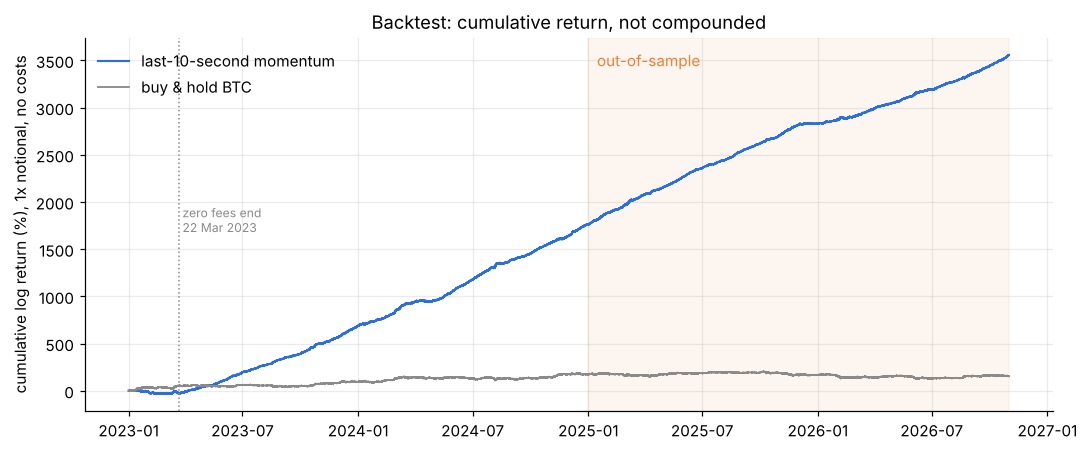

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(pnl.index, pnl.cumsum() * 100, color=BLUE, lw=1.4, label="last-10-second momentum")
ax.plot(bh.index, bh.cumsum() * 100, color=GREY, lw=1.2, label="buy & hold BTC")
ax.axvspan(pd.Timestamp(SPLIT), pnl.index[-1], color=ORANGE, alpha=0.08)
ax.axvline(pd.Timestamp("2023-03-22"), color=GREY, ls=":", lw=1)
ax.text(pd.Timestamp("2023-03-22"), ax.get_ylim()[1] * 0.45, " zero fees end\n 22 Mar 2023", color=GREY, fontsize=8)
ax.text(pd.Timestamp(SPLIT), ax.get_ylim()[1] * 0.92, "  out-of-sample", color=ORANGE)
ax.set_ylabel("cumulative log return (%), 1x notional, no costs")
ax.set_title("Backtest: cumulative return, not compounded"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig("fig_3_equity.png", bbox_inches="tight"); plt.show()

## 4 · Robustness

1. **Every year, and before vs after the 22 March 2023 break**. is the edge stable, and does it behave as the pattern predicts?
2. **Delay and holding period**. how quickly does the edge decay?
3. **Long vs short legs**. is it just riding the bull market?
4. **Signal-strength filter**. does trading only after large moves improve the edge per trade?

In [14]:
by_year = pd.DataFrame({
    "avg bp per minute": pnl.groupby(pnl.index.year).mean() * 1e4,
    "Sharpe": pnl.groupby(pnl.index.year).apply(lambda x: x.mean() / x.std() * np.sqrt(MIN_PER_YEAR)),
    "BTC price change": d["close"].groupby(d.index.year).agg(lambda x: x.iloc[-1] / x.iloc[0] - 1)})
print(by_year.round(3), "\n")

# the pattern predicts momentum only after zero fees ended (1-second returns were mean-reverting before)
pre, post_ = pnl[:"2023-03-21"], pnl["2023-03-23":]
pd.DataFrame({"zero-fee period (1 Jan - 21 Mar 2023)": [pre.mean() * 1e4, pre.sum() * 100],
              "after 22 Mar 2023": [post_.mean() * 1e4, post_.sum() / (len(post_) / MIN_PER_YEAR) * 100]},
             index=["avg bp per minute", "return (simple %, total / per yr)"]).round(3)

      avg bp per minute  Sharpe  BTC price change
2023              0.131  16.676             1.545
2024              0.204  20.319             1.118
2025              0.203  24.296            -0.073
2026              0.167  20.750            -0.127 



,zero-fee period (1 Jan - 21 Mar 2023),after 22 Mar 2023
avg bp per minute,-0.022,0.189
"return (simple %, total / per yr)",-25.007,992.526


In [15]:
lc = np.log(m["close"])
variants = {"baseline: enter now, hold 1 min": (position, fwd1),
            "enter 1 min late, hold 1 min": (position, fwd2),
            "enter now, hold 5 min (avg per min)": (position, (lc.shift(-5) - lc) / 5),
            "long leg only": (position.clip(lower=0), fwd1),
            "short leg only": (position.clip(upper=0), fwd1)}
rows = []
for name, (pos, fwd) in variants.items():
    p = (pos * fwd).fillna(0)
    rows.append({"variant": name,
                 "IS bp/min": p[IS].mean() * 1e4, "OOS bp/min": p[OOS].mean() * 1e4,
                 "IS Sharpe": p[IS].mean() / p[IS].std() * np.sqrt(MIN_PER_YEAR),
                 "OOS Sharpe": p[OOS].mean() / p[OOS].std() * np.sqrt(MIN_PER_YEAR)})
pd.DataFrame(rows).set_index("variant").round(3)

,IS bp/min,OOS bp/min,IS Sharpe,OOS Sharpe
variant,,,,
"baseline: enter now, hold 1 min",0.167,0.187,18.585,22.716
"enter 1 min late, hold 1 min",0.024,-0.002,2.655,-0.198
"enter now, hold 5 min (avg per min)",0.044,0.032,11.054,8.847
long leg only,0.091,0.091,14.406,15.727
short leg only,0.076,0.096,11.885,16.387


In [16]:
# signal strength: last-10s move relative to its typical size over the previous hour
typical_10s = np.sqrt(m["rv"].rolling(60).mean() * 10 / 60)
z = m["ret_last10s"] / typical_10s
rows = []
for thr in [0, 0.5, 1, 2]:
    pos = position.where(z.abs() > thr, 0).fillna(0)
    p = (pos * fwd1).fillna(0)
    act = pos != 0
    rows.append({"trade only if |move| > k x typical": thr, "time in market": act.mean(),
                 "IS bp per active min": p[IS][act[IS].values].mean() * 1e4,
                 "OOS bp per active min": p[OOS][act[OOS].values].mean() * 1e4,
                 "OOS Sharpe": p[OOS].mean() / p[OOS].std() * np.sqrt(MIN_PER_YEAR)})
pd.DataFrame(rows).set_index("trade only if |move| > k x typical").round(3)

,time in market,IS bp per active min,OOS bp per active min,OOS Sharpe
trade only if |move| > k x typical,,,,
0.0,0.811,0.203,0.234,22.716
0.5,0.397,0.271,0.287,18.101
1.0,0.227,0.287,0.264,12.474
2.0,0.075,0.264,0.164,4.076


### 4a · Sensitivity to the signal window (notebook 03)

The window length is the strategy's only parameter. I started with 10 seconds because the variance ratio already showed clear momentum at that horizon. To test this choice, notebook `03_signal_window_sensitivity.ipynb` re-downloads the 1-second data and repeats the strategy with windows of 2, 5, 10, 20 and 30 seconds (same rule, same periods, before costs).

| signal window | bp per minute 2023–24 | bp per minute 2025–Oct 2026 | Newey-West t 2025–Oct 2026 |
|---|---|---|---|
| last 2 s | 0.11 | 0.15 | 26 |
| last 5 s | 0.16 | 0.18 | 30 |
| **last 10 s** | **0.17** | **0.19** | **30** |
| last 20 s | 0.14 | 0.16 | 25 |
| last 30 s | 0.12 | 0.13 | 21 |

Three results matter. (1) Selecting the window on in-sample data alone (2023–24) gives 10 seconds, and out-of-sample 10 seconds is again in the best range. (2) Every window is profitable in both periods, so the conclusion does not depend on the exact choice. (3) The edge is highest for 5 to 10 seconds and declines gradually on either side; the difference between 5 and 10 seconds (0.18 vs 0.19 bp) is small relative to its estimation error. The same notebook shows that the variance ratio is already above 1 at 2 seconds after the break (median month 1.12, rising to 1.26 at 5 seconds), so momentum starts within a couple of seconds.

### 4b · A note on data snooping

While developing the strategy I looked at several candidate signals (whole minute, first 50 seconds, last 10 seconds, signal-strength filters) on the full sample. Choosing the best of many candidates inflates the apparent significance. Two checks limit this concern:

1. Using only the in-sample period (2023–24) to choose would have selected the same signal (last 10 seconds), so the out-of-sample period was never needed to make the choice.
2. Counting the window check in notebook 03, about 20 variants were tested. A Bonferroni-adjusted 5% threshold (two-sided) is then a t-statistic of about 3.0. The baseline signal's HAC t-statistics are about 25 in-sample and 30 out-of-sample, far above it.

A fully formal treatment would use White's (2000) Reality Check or Hansen's (2005) SPA test; I list this under next steps.

## 5 · Risk management

My aim in this section is to **control risk**, keeping the edge per trade intact while reducing the size of bad days. Two layers are added on top of the baseline signal, each with a single, economically motivated parameter.

**Why volatility matters here.** Section 2b showed that volatility clusters strongly. The table below groups minutes by recent volatility (average 1-second realized variance over the previous hour): the edge in bp is larger in volatile minutes, but the risk grows faster, so risk-adjusted performance is best in calm markets.

In [17]:
sigma = np.sqrt(m["rv"].rolling(60, min_periods=30).mean())       # recent 1-minute volatility from 1-second data
post = m.index >= "2023-04-01"
bucket = pd.qcut(sigma[post], 5, labels=["1 calmest", "2", "3", "4", "5 most volatile"])
tmp = pd.DataFrame({"pnl": pnl[post] * 1e4, "bucket": bucket})
vb = tmp.groupby("bucket", observed=True)["pnl"].agg(["mean", "std"])
vb.columns = ["avg bp per minute", "std of bp per minute"]
vb["mean / std (per minute)"] = vb.iloc[:, 0] / vb.iloc[:, 1]
vb["volatility range (bp per min)"] = sigma[post].groupby(bucket, observed=True).agg(lambda x: f"{x.min()*1e4:.1f} to {x.max()*1e4:.1f}")
vb.round(3)

,avg bp per minute,std of bp per minute,mean / std (per minute),volatility range (bp per min)
bucket,,,,
1 calmest,0.164,2.010,0.082,0.0 to 2.0
2,0.216,3.240,0.067,2.0 to 2.9
3,0.216,4.418,0.049,2.9 to 3.9
4,0.166,6.028,0.028,3.9 to 5.8
5 most volatile,0.183,11.040,0.017,5.8 to 116.3


**Layer 1, volatility-targeted sizing.** Position size is scaled so that the risk taken per minute stays roughly constant (Moreira and Muir, 2017):
$$\text{size}_t = \min\left(\frac{\sigma_{\text{ref}}}{\hat\sigma_t},\ 2\right)$$
$\hat\sigma_t$ is recent volatility (previous hour, from 1-second data) and $\sigma_{\text{ref}}$ is the median of $\hat\sigma$ over the **previous 90 days**, updated monthly, so only past information is used. The cap of 2× prevents very large positions in unusually quiet periods (without it, size would reach several hundred times notional). Because the reference needs 90 days of post-break history, results in this section start in **July 2023**.

**Layer 2, daily loss limit.** If cumulative P&L for the day (UTC) falls below −1.5%, the strategy stops trading until the next day. The level is set relative to the strategy's own daily volatility (standard deviation of daily P&L ≈ 2.3% in 2023–24, so the limit is about 0.65 standard deviations). I tested 1%, 1.5%, 2% and 3%: 1% triggers on about one day in eight and mostly cuts normal fluctuations, while 1.5% roughly halves the worst day at almost no cost to returns.

In [18]:
ref = pd.Series(np.nan, index=m.index)
for mo in pd.period_range("2023-07", m.index[-1].strftime("%Y-%m"), freq="M"):
    start = mo.start_time
    ref[(m.index >= start) & (m.index <= mo.end_time)] = sigma[start - pd.Timedelta(days=90): start - pd.Timedelta(minutes=1)].median()
size = (ref / sigma).clip(upper=2)
pos_vt = (position * size).fillna(0)
pnl_vt = (pos_vt * fwd1).fillna(0)

def daily_stop(pnl_min, limit):
    day = pnl_min.index.floor("D")
    cum_before = pnl_min.groupby(day).cumsum().groupby(day).shift(1).fillna(0)   # P&L up to the previous minute
    stopped = (cum_before < -limit).groupby(day).cummax()
    return pnl_min.where(~stopped, 0), stopped.groupby(day).any()

def risk_metrics(p, pos, label, stopped_days=None):
    dd_ = p.resample("1D").sum(); c = p.cumsum()
    changes = pos.diff().abs().fillna(0).sum()
    out = {"version": label,
           "avg bp per minute": p.mean() * 1e4,
           "breakeven cost (bp)": p.sum() / changes * 1e4,
           "return (simple, %/yr)": p.sum() / (len(p) / MIN_PER_YEAR) * 100,
           "Sharpe (ann.)": p.mean() / p.std() * np.sqrt(MIN_PER_YEAR),
           "worst day (%)": dd_.min() * 100,
           "max drawdown (%)": (c - c.cummax()).min() * 100,
           "positive days": (dd_ > 0).mean()}
    out["limit triggered (share of days)"] = stopped_days.mean() if stopped_days is not None else 0.0
    return out

periods = {"Jul 2023 - Dec 2024": (m.index >= "2023-07-01") & (m.index < SPLIT), "2025 - Oct 2026": m.index >= SPLIT}
rows = []
for pname, mask in periods.items():
    base = pnl[mask]; vt = pnl_vt[mask]
    rows.append({"period": pname, **risk_metrics(base, position[mask], "1 baseline (1x)")})
    rows.append({"period": pname, **risk_metrics(vt, pos_vt[mask], "2 + vol targeting (cap 2x)")})
    vt_stop, st = daily_stop(vt, 0.015)
    rows.append({"period": pname, **risk_metrics(vt_stop, pos_vt[mask].where(vt_stop != 0, 0), "3 + daily loss limit 1.5% (final)", st)})
risk_table = pd.DataFrame(rows).set_index(["period", "version"])
risk_table.round(3)

avg bp per minute  \
period              version                                                
Jul 2023 - Dec 2024 1 baseline (1x)                                0.197   
                    2 + vol targeting (cap 2x)                     0.209   
                    3 + daily loss limit 1.5% (final)              0.203   
2025 - Oct 2026     1 baseline (1x)                                0.187   
                    2 + vol targeting (cap 2x)                     0.207   
                    3 + daily loss limit 1.5% (final)              0.203   

                                                       breakeven cost (bp)  \
period              version                                                  
Jul 2023 - Dec 2024 1 baseline (1x)                                  0.213   
                    2 + vol targeting (cap 2x)                       0.218   
                    3 + daily loss limit 1.5% (final)                0.224   
2025 - Oct 2026     1 baseline (1x)                                  0.200   
                    2 + vol targeting (cap 2x)                       0.201   
                    3 + daily loss limit 1.5% (final)                0.208   

                                                       return (simple, %/yr)  \
period              version                                                    
Jul 2023 - Dec 2024 1 baseline (1x)                                 1037.808   
                    2 + vol targeting (cap 2x)                      1097.281   
                    3 + daily loss limit 1.5% (final)               1064.567   
2025 - Oct 2026     1 baseline (1x)                                  980.743   
                    2 + vol targeting (cap 2x)                      1087.639   
                    3 + daily loss limit 1.5% (final)               1066.077   

                                                       Sharpe (ann.)  \
period              version                                            
Jul 2023 - Dec 2024 1 baseline (1x)                           21.669   
                    2 + vol targeting (cap 2x)                34.207   
                    3 + daily loss limit 1.5% (final)         33.959   
2025 - Oct 2026     1 baseline (1x)                           22.716   
                    2 + vol targeting (cap 2x)                34.623   
                    3 + daily loss limit 1.5% (final)         34.613   

                                                       worst day (%)  \
period              version                                            
Jul 2023 - Dec 2024 1 baseline (1x)                           -9.003   
                    2 + vol targeting (cap 2x)                -3.455   
                    3 + daily loss limit 1.5% (final)         -1.673   
2025 - Oct 2026     1 baseline (1x)                           -7.132   
                    2 + vol targeting (cap 2x)                -2.941   
                    3 + daily loss limit 1.5% (final)         -1.708   

                                                       max drawdown (%)  \
period              version                                               
Jul 2023 - Dec 2024 1 baseline (1x)                             -20.164   
                    2 + vol targeting (cap 2x)                   -6.679   
                    3 + daily loss limit 1.5% (final)            -6.619   
2025 - Oct 2026     1 baseline (1x)                             -20.198   
                    2 + vol targeting (cap 2x)                   -7.368   
                    3 + daily loss limit 1.5% (final)            -7.548   

                                                       positive days  \
period              version                                            
Jul 2023 - Dec 2024 1 baseline (1x)                            0.878   
                    2 + vol targeting (cap 2x)                 0.936   
                    3 + daily loss limit 1.5% (final)          0.909   
2025 - Oct 2026     1 baseline (1x)                            0.

In [19]:
# calibration of the daily loss limit (final sizing, both periods)
rows = []
for limit in [None, 0.01, 0.015, 0.02, 0.03]:
    for pname, mask in periods.items():
        vt = pnl_vt[mask]
        p, st = (vt, None) if limit is None else daily_stop(vt, limit)
        dd_ = p.resample("1D").sum()
        rows.append({"daily loss limit": "none" if limit is None else f"{limit:.1%}", "period": pname,
                     "triggered (share of days)": 0.0 if st is None else st.mean(),
                     "worst day (%)": dd_.min() * 100, "Sharpe (ann.)": p.mean() / p.std() * np.sqrt(MIN_PER_YEAR),
                     "positive days": (dd_ > 0).mean()})
print(f"standard deviation of daily P&L with vol targeting, Jul 2023 - Dec 2024: {pnl_vt[periods['Jul 2023 - Dec 2024']].resample('1D').sum().std()*100:.2f}%")
pd.DataFrame(rows).set_index(["daily loss limit", "period"]).round(3)

standard deviation of daily P&L with vol targeting, Jul 2023 - Dec 2024: 2.29%


triggered (share of days)  \
daily loss limit period                                           
none             Jul 2023 - Dec 2024                      0.000   
                 2025 - Oct 2026                          0.000   
1.0%             Jul 2023 - Dec 2024                      0.120   
                 2025 - Oct 2026                          0.130   
1.5%             Jul 2023 - Dec 2024                      0.060   
                 2025 - Oct 2026                          0.066   
2.0%             Jul 2023 - Dec 2024                      0.024   
                 2025 - Oct 2026                          0.030   
3.0%             Jul 2023 - Dec 2024                      0.007   
                 2025 - Oct 2026                          0.001   

                                      worst day (%)  Sharpe (ann.)  \
daily loss limit period                                              
none             Jul 2023 - Dec 2024         -3.455         34.207   
                 2025 - Oct 2026             -2.941         34.623   
1.0%             Jul 2023 - Dec 2024         -1.303         33.852   
                 2025 - Oct 2026             -1.177         34.308   
1.5%             Jul 2023 - Dec 2024         -1.673         33.959   
                 2025 - Oct 2026             -1.708         34.613   
2.0%             Jul 2023 - Dec 2024         -2.288         34.234   
                 2025 - Oct 2026             -2.067         34.540   
3.0%             Jul 2023 - Dec 2024         -3.026         34.187   
                 2025 - Oct 2026             -3.006         34.623   

                                      positive days  
daily loss limit period                              
none             Jul 2023 - Dec 2024          0.936  
                 2025 - Oct 2026              0.921  
1.0%             Jul 2023 - Dec 2024          0.862  
                 2025 - Oct 2026              0.855  
1.5%             Jul 2023 - Dec 2024          0.909  
                 2025 - Oct 2026              0.900  
2.0%             Jul 2023 - Dec 2024          0.931  
                 2025 - Oct 2026              0.913  
3.0%             Jul 2023 - Dec 2024          0.936  
                 2025 - Oct 2026              0.921

In [20]:
# alternative I compared: a simple on/off volatility switch (trade only when recent volatility is below its 90-day 80th percentile)
ref80 = pd.Series(np.nan, index=m.index)
for mo in pd.period_range("2023-07", m.index[-1].strftime("%Y-%m"), freq="M"):
    start = mo.start_time
    ref80[(m.index >= start) & (m.index <= mo.end_time)] = sigma[start - pd.Timedelta(days=90): start - pd.Timedelta(minutes=1)].quantile(0.8)
pos_sw = position.where(sigma <= ref80, 0).fillna(0)
pnl_sw = (pos_sw * fwd1).fillna(0)
rows = []
for pname, mask in periods.items():
    p, st = daily_stop(pnl_sw[mask], 0.015)
    rows.append({"period": pname, **risk_metrics(p, pos_sw[mask].where(p != 0, 0), "vol switch + daily limit 1.5%", st)})
pd.DataFrame(rows).set_index(["period", "version"]).round(3)

,,avg bp per minute,breakeven cost (bp),"return (simple, %/yr)",Sharpe (ann.),worst day (%),max drawdown (%),positive days,limit triggered (share of days)
period,version,,,,,,,,
Jul 2023 - Dec 2024,vol switch + daily limit 1.5%,0.149,0.223,783.863,28.369,-1.648,-6.908,0.884,0.058
2025 - Oct 2026,vol switch + daily limit 1.5%,0.147,0.207,770.830,28.923,-1.630,-7.606,0.880,0.048


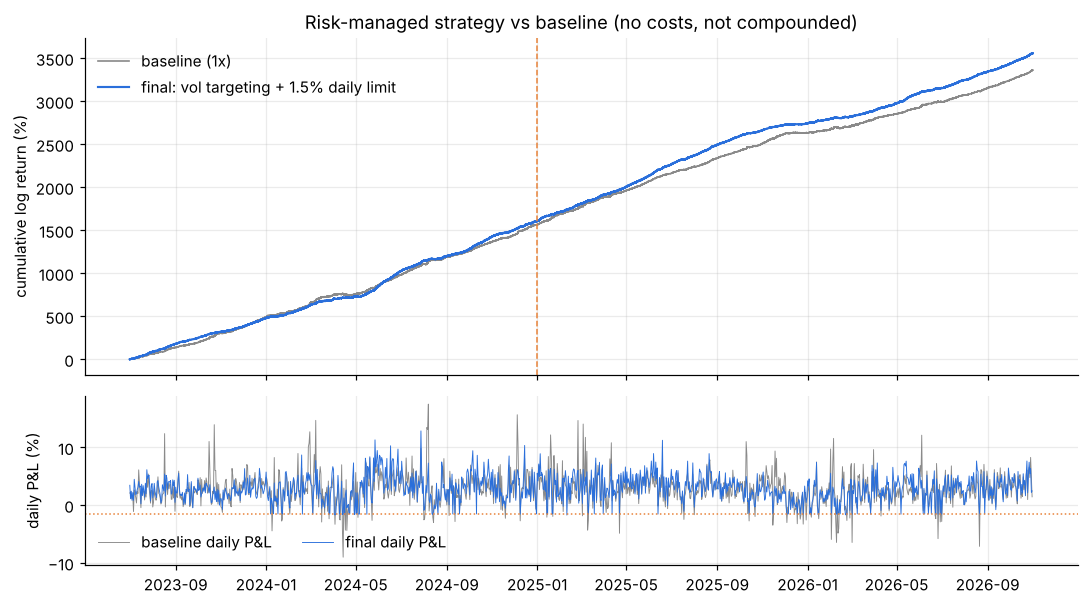

In [21]:
final_pnl = pd.concat([daily_stop(pnl_vt[mask], 0.015)[0] for mask in periods.values()]).sort_index().reindex(m.index).fillna(0)
fig, ax = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
start = "2023-07-01"
ax[0].plot(pnl[start:].cumsum() * 100, color=GREY, lw=1.1, label="baseline (1x)")
ax[0].plot(final_pnl[start:].cumsum() * 100, color=BLUE, lw=1.4, label="final: vol targeting + 1.5% daily limit")
ax[0].axvline(pd.Timestamp(SPLIT), color=ORANGE, ls="--", lw=1)
ax[0].set_ylabel("cumulative log return (%)"); ax[0].legend(frameon=False, loc="upper left")
ax[0].set_title("Risk-managed strategy vs baseline (no costs, not compounded)")
db, df_ = pnl[start:].resample("1D").sum() * 100, final_pnl[start:].resample("1D").sum() * 100
ax[1].plot(db, color=GREY, lw=0.6, label="baseline daily P&L"); ax[1].plot(df_, color=BLUE, lw=0.6, label="final daily P&L")
ax[1].axhline(-1.5, color=ORANGE, ls=":", lw=1); ax[1].set_ylabel("daily P&L (%)"); ax[1].legend(frameon=False, ncol=2, loc="lower left")
plt.tight_layout(); plt.savefig("fig_4_risk.png", bbox_inches="tight"); plt.show()

## 6 · Comparison with classic BTC strategies

To put the result in context I compare it with well-known rules that use only price data, all computed on the same minute bars and evaluated with the same conventions (daily rules are decided at the UTC daily close and applied from the next minute onwards):

- **Buy & hold.**
- **Time-series momentum** (Moskowitz, Ooi and Pedersen, 2012): long if the past 30-day return is positive, short otherwise.
- **Moving-average crossover**: long if the 20-day average is above the 50-day average, short otherwise.
- **Donchian breakout**: long after a close above the previous 20-day high, short after a close below the previous 20-day low, otherwise keep the position.
- **RSI(14) mean reversion**: long when RSI < 30, short when RSI > 70, flat otherwise.
- **Hourly momentum**: the sign of the previous hour's return.

In [22]:
close_d = m["close"].resample("1D").last()
ret_d = np.log(close_d).diff()
def to_minutes(daily_pos):          # decided at the daily close, applied to the following day's minutes
    return daily_pos.shift(1).reindex(m.index, method="ffill").fillna(0)

tsmom = np.sign(np.log(close_d).diff(30))
ma = np.sign(close_d.rolling(20).mean() - close_d.rolling(50).mean())
hi, lo = close_d.rolling(20).max().shift(1), close_d.rolling(20).min().shift(1)
donch = pd.Series(np.where(close_d > hi, 1, np.where(close_d < lo, -1, np.nan)), index=close_d.index).ffill().fillna(0)
gain, loss = ret_d.clip(lower=0).rolling(14).mean(), (-ret_d.clip(upper=0)).rolling(14).mean()
rsi = 100 - 100 / (1 + gain / loss)
rsi_pos = pd.Series(np.where(rsi < 30, 1, np.where(rsi > 70, -1, 0)), index=close_d.index)
hourly = np.sign(np.log(m["close"].resample("1h").last()).diff()).shift(1).reindex(m.index, method="ffill").fillna(0)

classic = {"buy & hold": pd.Series(1.0, index=m.index), "time-series momentum (30d)": to_minutes(tsmom),
           "MA crossover (20d / 50d)": to_minutes(ma), "Donchian breakout (20d)": to_minutes(donch),
           "RSI(14) mean reversion": to_minutes(rsi_pos), "hourly momentum": hourly,
           "last-10s momentum, baseline": position, "last-10s momentum, final (risk-managed)": None}
rows = []
for pname, mask in periods.items():
    for name, pos in classic.items():
        if pos is None:
            p, pz = final_pnl[mask], pos_vt[mask]
        else:
            p, pz = (pos * fwd1).fillna(0)[mask], pos[mask]
        dd_ = p.resample("1D").sum(); c = p.cumsum()
        rows.append({"strategy": name, "period": pname,
                     "return (simple, %/yr)": p.sum() / (len(p) / MIN_PER_YEAR) * 100,
                     "Sharpe (daily, ann.)": dd_.mean() / dd_.std() * np.sqrt(365),
                     "max drawdown (%)": (c - c.cummax()).min() * 100,
                     "worst day (%)": dd_.min() * 100})
classic_table = pd.DataFrame(rows).set_index(["period", "strategy"])
classic_table.round(2)

return (simple, %/yr)  \
period              strategy                                                         
Jul 2023 - Dec 2024 buy & hold                                               74.46   
                    time-series momentum (30d)                               32.86   
                    MA crossover (20d / 50d)                                 21.62   
                    Donchian breakout (20d)                                  49.20   
                    RSI(14) mean reversion                                  -36.84   
                    hourly momentum                                         -76.97   
                    last-10s momentum, baseline                            1037.81   
                    last-10s momentum, final (risk-managed)                1064.57   
2025 - Oct 2026     buy & hold                                              -10.25   
                    time-series momentum (30d)                               15.94   
                    MA crossover (20d / 50d)                                 28.96   
                    Donchian breakout (20d)                                   2.22   
                    RSI(14) mean reversion                                    2.46   
                    hourly momentum                                          -0.21   
                    last-10s momentum, baseline                             980.74   
                    last-10s momentum, final (risk-managed)                1066.08   

                                                             Sharpe (daily, ann.)  \
period              strategy                                                        
Jul 2023 - Dec 2024 buy & hold                                               1.55   
                    time-series momentum (30d)                               0.68   
                    MA crossover (20d / 50d)                                 0.45   
                    Donchian breakout (20d)                                  1.02   
                    RSI(14) mean reversion                                  -1.25   
                    hourly momentum                                         -1.87   
                    last-10s momentum, baseline                             19.34   
                    last-10s momentum, final (risk-managed)                 23.32   
2025 - Oct 2026     buy & hold                                              -0.24   
                    time-series momentum (30d)                               0.37   
                    MA crossover (20d / 50d)                                 0.68   
                    Donchian breakout (20d)                                  0.05   
                    RSI(14) mean reversion                                   0.09   
                    hourly momentum                                         -0.01   
                    last-10s momentum, baseline                             19.30   
                    last-10s momentum, final (risk-managed)                 25.37   

                                                             max drawdown (%)  \
period              strategy                                                    
Jul 2023 - Dec 2024 buy & hold                                         -40.23   
                    time-series momentum (30d)                         -87.72   
                    MA crossover (20d / 50d)                           -76.57   
                    Donchian breakout (20d)                            -61.08   
                    RSI(14) mean reversion                             -83.66   
                    hourly momentum                                   -138.63   
                    last-10s momentum, baseline                        -20.16   
                    last-10s momentum, final (risk-managed)             -6.62   
2025 - Oct 2026     buy & hold                                         -77.88   
                    time-series momentum (30d)                         -42.31   
         

The classic rules trade a few times a month and their results depend heavily on the market trend of each period. The last-10-second strategy is close to market-neutral and profitable in both periods, but it trades hundreds of thousands of times a year, so the comparison only holds before costs (section 8). Sharpe ratios here are computed from daily P&L so that all strategies are measured the same way, and drawdowns are in cumulative log-return points (uncompounded).

## 7 · Market context: major news days

BTC is driven by macro news, regulation and leverage in the crypto market. I checked how the strategy behaved on the most volatile days in the sample and on several well-documented events. Sources for each event are linked. Because the strategy follows short-term moves, it tends to **gain** on crash days, when moves continue for longer; volatility targeting deliberately reduces size on those days, which lowers the gain but also protects against the days when the pattern breaks.

| date | event | source |
|---|---|---|
| 13 Mar 2023 | rally after US authorities backstop SVB depositors; USDC regains its peg | [The Block](https://www.theblock.co/post/219217/bitcoin-hurtles-back-above-23000-as-crypto-prices-buoyed-amid-us-banking-woes) |
| 10 Jan 2024 | SEC approves 11 spot bitcoin ETFs | [The Block](https://www.theblock.co/post/271324/the-sec-said-it-has-approved-proposals-for-spot-bitcoin-etfs-on-an-accelerated-basis) |
| 5 Aug 2024 | global sell-off as the yen carry trade unwinds | [CoinDesk](https://coindesk.com/markets/2024/08/05/bitcoin-drops-15-against-japanese-yen-outpacing-declines-versus-usd-as-yen-carry-trades-unwind) |
| 7 Apr 2025 | sell-off after the US tariff announcements | [The Block](https://www.theblock.co/post/349765/sell-now-think-later-stampede-sends-bitcoin-ether-tumbling-alongside-asian-stocks-analyst-says) |
| 10 Oct 2025 | 100% China tariff threat, record crypto liquidations | [PYMNTS](https://www.pymnts.com/cryptocurrency/2025/tariffs-trigger-record-19-billion-in-crypto-liquidations/) |
| 5 Feb 2026 | flash crash towards $60,000 | [The Block](https://www.theblock.co/post/388759/bitcoin-sees-flash-crash-60000) |

In [23]:
events = ["2023-03-13", "2024-01-10", "2024-08-05", "2025-04-07", "2025-10-10", "2026-02-05"]
d_vol = np.sqrt(m["rv"].resample("1D").sum() * 365) * 100
base_d, final_d = pnl.resample("1D").sum() * 100, final_pnl["2023-07-01":].resample("1D").sum() * 100
ev = pd.DataFrame({"BTC daily return (%)": ret_d.reindex(pd.to_datetime(events)) * 100,
                   "annualised vol that day (%)": d_vol.reindex(pd.to_datetime(events)),
                   "baseline strategy P&L (%)": base_d.reindex(pd.to_datetime(events)),
                   "final strategy P&L (%)": final_d.reindex(pd.to_datetime(events))})
ev.index = ev.index.date
ev["final strategy P&L (%)"] = ev["final strategy P&L (%)"].round(2).astype(object).where(ev["final strategy P&L (%)"].notna(), "n/a (sizing starts Jul 2023)")
print("Event days:"); display(ev.round(2))

top = d_vol.loc["2023-04-01":].sort_values(ascending=False).head(15).index
hv = pd.DataFrame({"share of days with positive P&L": [(base_d[top] > 0).mean(), (final_d.reindex(top) > 0).mean(), (final_d > 0).mean()],
                   "avg daily P&L (%)": [base_d[top].mean(), final_d.reindex(top).mean(), final_d.mean()]},
                  index=["baseline, 15 most volatile days", "final, 15 most volatile days", "final, all days"])
hv.round(2)

Event days:


,BTC daily return (%),annualised vol that day (%),baseline strategy P&L (%),final strategy P&L (%)
2023-03-13,9.19,100.40,2.17,n/a (sizing starts Jul 2023)
2024-01-10,1.17,98.23,-0.03,-0.32
2024-08-05,-7.39,184.10,13.46,2.12
2025-04-07,0.93,99.05,-0.30,2.1
2025-10-10,-7.59,181.74,11.02,4.98
2026-02-05,-15.10,125.69,11.57,2.57


,share of days with positive P&L,avg daily P&L (%)
"baseline, 15 most volatile days",0.8,6.38
"final, 15 most volatile days",0.8,2.21
"final, all days",0.9,2.92


## 8 · Cost sensitivity

The brief excludes transaction costs, but the edge per trade is small, so it matters how much cost the strategy can absorb. The **breakeven cost** is total gross profit divided by total units traded: about 0.2 bp per unit, while Binance's standard spot fee is 10 bp (0.10%) per side ([Binance fee schedule](https://www.binance.com/en/fee/schedule)). Below, net performance is recomputed for a range of costs per unit traded.

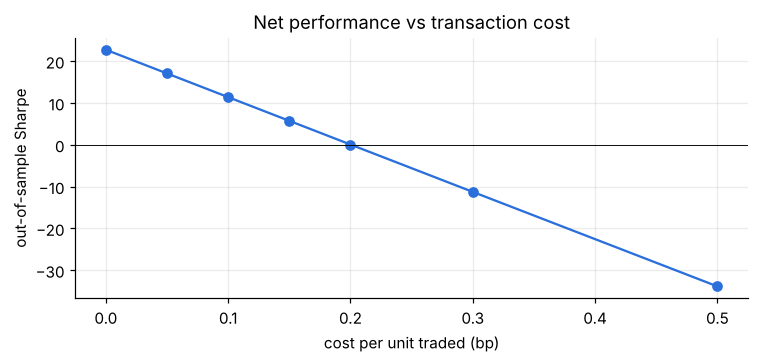

trades (position changes) per year: 490,213


,cost per unit traded (bp),"OOS net return (simple, %/yr)",OOS net Sharpe
0,0.00,980.74,22.72
1,0.05,736.08,17.05
2,0.10,491.42,11.38
3,0.15,246.75,5.71
4,0.20,2.09,0.05
5,0.30,-487.23,-11.28
6,0.50,-1465.88,-33.87


In [24]:
units = position.diff().abs().fillna(0)
costs_bp = [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
net = pd.DataFrame({"cost per unit traded (bp)": costs_bp,
                    "OOS net return (simple, %/yr)": [((pnl - c / 1e4 * units)[OOS]).sum() / (OOS.sum() / MIN_PER_YEAR) * 100 for c in costs_bp],
                    "OOS net Sharpe": [(lambda x: x.mean() / x.std() * np.sqrt(MIN_PER_YEAR))((pnl - c / 1e4 * units)[OOS]) for c in costs_bp]})
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(net.iloc[:, 0], net.iloc[:, 2], "o-", color=BLUE); ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("cost per unit traded (bp)"); ax.set_ylabel("out-of-sample Sharpe")
ax.set_title("Net performance vs transaction cost")
plt.tight_layout(); plt.savefig("fig_5_costs.png", bbox_inches="tight"); plt.show()
print(f"trades (position changes) per year: {units.sum() / (len(units) / MIN_PER_YEAR):,.0f}")
net.round(2)

## 9 · Conclusions

- **Pattern.** Since Binance ended zero-fee BTC/USDT trading on 22 March 2023, BTC/USDT shows short-horizon momentum: price moves over a few seconds tend to continue (variance ratios above 1, positive 1-second autocorrelation in almost every month).
- **Strategy.** Trading in the direction of the last 10 seconds of each minute (the window selected on in-sample data from 2 to 30 seconds), held for one minute, is profitable before costs in every year after the break, with similar performance in-sample and out-of-sample.
- **Why it is credible.** It has one parameter (the window), selected on in-sample data; it works for any signal window from 2 to 30 seconds and for both long and short legs, and it fails exactly where the pattern says it should: it lost money in the zero-fee period, and entering one minute late removes the edge.
- **Risk management.** Volatility-targeted sizing (cap 2×) and a 1.5% daily loss limit reduce the worst day from about −9% (in-sample) and −7% (out-of-sample) to about −1.7%, and the maximum drawdown from about −20% to about −7%, while the edge per trade stays at about 0.2 bp per minute.
- **What it is worth in practice.** The edge is about 0.2 bp per minute and breakeven cost is about 0.2 bp per unit traded, far below standard exchange fees. As a stand-alone strategy it is only exploitable by very low-cost, low-latency participants. Its most direct use is **execution timing**: a desk that already has to buy or sell BTC (for example when creating or redeeming ETP units) can use the direction of the last 10 seconds to decide whether to execute now or wait a minute, where the cost is paid anyway and the signal improves the fill.

### Limitations
- Execution is assumed at the minute close with no latency or slippage.
- One venue (Binance spot) and one pair; no order-book data.
- Several signals were compared during development (see 4b); a formal Reality Check has not been run.
- Returns are uncompounded, on 1× notional (up to 2× with sizing), and before costs.

### Next steps
1. **Volatility-scaled take-profit and stop-loss** (ATR multiples) on each trade, tested on the 1-second data.
2. **Latency test**: re-run with entry 1, 2, 5 seconds after the minute close, using the 1-second data directly.
3. **Execution test with order-book data**: can passive (maker) orders capture the edge?
4. **Better intraday volatility models**: HAR-RV (Corsi, 2009) or an intraday GARCH on deseasonalized returns (Andersen and Bollerslev, 1997) to replace the simple one-hour volatility estimate.
5. **Formal data-snooping test**: White's Reality Check / Hansen's SPA across all variants.

## Appendix A · Time of day
Average strategy return by hour of the day (UTC), after the structural break. Activity follows the Asian, European and US sessions.

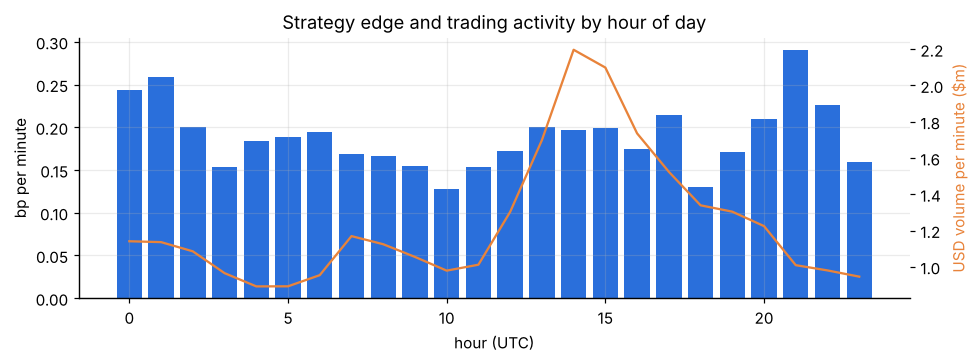

,avg bp per minute,avg USD volume per minute ($m)
0,0.244,1.141
1,0.258,1.136
2,0.201,1.085
3,0.153,0.965
4,0.184,0.892
5,0.189,0.892
6,0.194,0.954
7,0.168,1.169
8,0.167,1.124
9,0.154,1.054


In [25]:
after = pnl["2023-04-01":]
tod = pd.DataFrame({"avg bp per minute": after.groupby(after.index.hour).mean() * 1e4,
                    "avg USD volume per minute ($m)": m.loc["2023-04-01":, "quote_volume"].groupby(m.loc["2023-04-01":].index.hour).mean() / 1e6})
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(tod.index, tod["avg bp per minute"], color=BLUE); ax.set_xlabel("hour (UTC)"); ax.set_ylabel("bp per minute")
ax2 = ax.twinx(); ax2.plot(tod.index, tod.iloc[:, 1], color=ORANGE, lw=1.5); ax2.set_ylabel("USD volume per minute ($m)", color=ORANGE)
ax2.grid(False); ax.set_title("Strategy edge and trading activity by hour of day")
plt.tight_layout(); plt.savefig("fig_A_time_of_day.png", bbox_inches="tight"); plt.show()
tod.round(3)